# Modularity on the Karate Club Graph


#1. Introduction
 The Karate Club Graph is a social network that represents the friendship relations between the members of a karate club at a university. The current work uses spectral partitioning with modularity optimization to discover communities within the network and study their dependence on node parameters.

## 2. Objectives

The goals of the research include an analysis of the community structure of the Karate Club Graph using recursive spectral modularity partitioning. The goals are as follows:

1. To conduct recursive spectral partitioning of the graph based on modularity optimization to find the communities in the graph.
2. To show the found community structure at each step of partitioning in order to demonstrate the process of partitioning.
3. To calculate the node-level network metrics such as degree centrality, betweenness centrality, closeness centrality, and clustering coefficient.
4. To investigate the change of the chosen network metrics during the partitioning process by means of visualization.
5. To interpret the results by detecting structurally significant nodes and analyzing the connection between the community structure and the network metrics.

##3. Theory

###  Graph

A graph is a mathematical object composed of vertices (nodes) and edges that connect pairs of nodes. In social network analysis, nodes stand for individuals and edges for the relations between them.

The Karate Club Graph is an undirected social network where each node stands for a member of a karate club and each edge corresponds to the friendship between two members. It is convenient to use it for analysis of relations between individuals and identification of communities in this network.

###  Community

Community is a set of nodes with relatively high density of connections among them and lower connections to other nodes. Community detection is an attempt to discover such communities in the network.

In the Karate Club Graph, the process of community detection allows one to reveal such communities among the members of this karate club.

###  Modularity

Modularity is a quantity used in assessing the quality of a partition of a network into communities. This quantity makes the comparison between the observed edge counts between nodes belonging to the same community and the edge counts expected based on a certain null model.

Generally, a large positive value of modularity usually implies that the network partition has relatively more within-community edges compared to what is expected by the null model.

Modularity of an undirected graph can be defined as
   
   $$
Q = \frac{1}{2m}
\sum_{i=1}^{n}\sum_{j=1}^{n}
\left(
A_{ij} - \frac{k_i k_j}{2m}
\right)
\delta(c_i,c_j)
$$

where

- \(Q\) is the modularity measure.
- \(m\) is the total number of edges in the graph.
- \(Aij\) is the element of the adjacency matrix of nodes \(i\) and \(j\).
- \(ki\) and \(kj\) are the degree values of nodes \(i\) and \(j\).
- \(ci\) and \(cj\) are the communities of nodes \(i\) and \(j\).
- \$\delta(c_i,c_j)$=1  if nodes belong to the same community, otherwise 0.

In the current project, modularity is used to assess community partitions produced by recursive spectral bisection.

###  Spectral Partitioning

Spectral partitioning is a technique for partitioning graphs based on the use of the eigenvalues and eigenvectors of a matrix, which represents the structure of the network.

Modularity based spectral partitioning uses the modularity matrix for finding a split of the network, which would help to increase modularity. The eigenvector of the modularity matrix corresponding to the maximum eigenvalue is used for identifying a possible splitting of the nodes into two classes.

The sign of each element of this eigenvector is used to classify the nodes to different communities. The corresponding change in modularity of the proposed partition is evaluated and checked for its optimality.

In the current project, spectral partitioning is carried out recursively, i.e. each found community could be further partitioned using the spectral partitioning algorithm in case there is a positive modularity gain from such split.





#   Implementation

In this section we will discuss about the implementation of recursive spectral modularity clustering algorithm on the Karate Club graph. It covers graph generation, community detection, visualization, calculation of metrics on nodes level, and analysis of the connection between the metrics and the communities.

###  Importing Libraries

The following Python libraries have been utilized in this project:

1. **NetworkX**: It has been employed to construct, load, and analyze the Karate Club Graph.
2. **NumPy**: It has been used for computing mathematical calculations such as eigenvectors and eigenvalues.
3. **Matplotlib**: This library has been used for visualization of the graph and communities.
4. **Pandas** :This library is used for organize and display network metrics in a tabular format, with nodes as rows and metrics as columns.

##  Loading the Karate Club Graph

The Karate Club Graph is one of the built-in datasets in NetworkX. The dataset captures friendship relations among 34 individuals of a university karate club and includes 78 edges.

In the current project, the Karate Club Graph will be used as the input to perform recursive spectral modularity clustering.

##  Graph Properties Inspection

Prior to performing the community detection procedure, some basic properties of the Karate Club Graph are inspected. The inspection gives an idea about the nature of the graph as well as ensures that the data has been imported properly.

In [3]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
g=nx.karate_club_graph()
n=nx.number_of_nodes(g)
m=nx.number_of_edges(g)
if nx.is_connected(g):
  print("Graph is connected")
else:
  print("Graph is not connected")
print("Number of nodes :",n,"\nNumber of edges :",m)


Graph is connected
Number of nodes : 34 
Number of edges : 78


 ## Visualization of the Original Graph

The visualization of the original graph gives us an insight into the entire network structure before community detection. Here nodes represent members of the club, and edges depict the connections among members as friends. This serves as a reference against which we can compare our network and the detected communities.

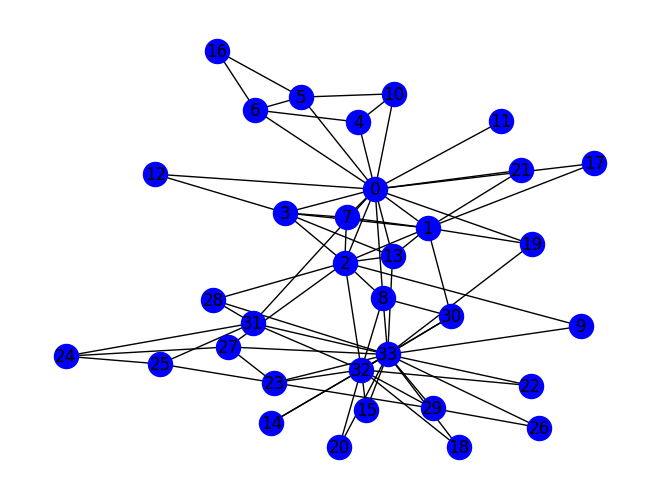

In [4]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
g=nx.karate_club_graph()
nx.draw(g,with_labels=True,node_color='blue')
plt.show()

## Building the Modularity Matrix

The modularity matrix is a matrix which is used to analyze the community structure of the network. Every element of the modularity matrix gives us the difference between the actual and expected connection between two nodes.

For the case of an undirected graph, the modularity matrix can be represented by the following equation:

$$
B_{ij}=A_{ij}-\frac{k_i k_j}{2m}
$$

where:

- \$(B_{ij}\)$ is the entry of the modularity matrix for the nodes \(i\) and \(j\).
- \$(A_{ij}\$) is the entry of the adjacency matrix.
- \$(k_i\$) and \$(k_j\$) are the degrees of the nodes \(i\) and \(j\).
- \(m\) is the number of the edges.

In [5]:
import numpy as np
import networkx as nx
g=nx.karate_club_graph()
A = nx.to_numpy_array(g, weight=None)
x= np.array([g.degree(i) for i in g.nodes()])
m=nx.number_of_edges(g)
B=A-np.outer(x,x)/(2*m)
print("The modularity matrix of karate graph \n")
print(B)
#

The modularity matrix of karate graph 

[[-1.64102564  0.07692308 -0.02564103 ...  0.38461538 -1.23076923
  -1.74358974]
 [ 0.07692308 -0.51923077  0.42307692 ... -0.34615385 -0.69230769
  -0.98076923]
 [-0.02564103  0.42307692 -0.64102564 ... -0.38461538  0.23076923
  -1.08974359]
 ...
 [ 0.38461538 -0.34615385 -0.38461538 ... -0.23076923  0.53846154
   0.34615385]
 [-1.23076923 -0.69230769  0.23076923 ...  0.53846154 -0.92307692
  -0.30769231]
 [-1.74358974 -0.98076923 -1.08974359 ...  0.34615385 -0.30769231
  -1.8525641 ]]


## Eigenvalue and Eigenvector Calculation

Calculation of eigenvalue and eigenvector is performed on the modularity matrix to look for possible divisions in the Karate Club Graph. The eigenvector that corresponds to the largest eigenvalue can be utilized for finding a possible partition of the graph into two parts.

In [6]:
import numpy as np
import networkx as nx
g=nx.karate_club_graph()
eigval,eigvect=np.linalg.eigh(B)
eigmax=eigval[-1]
v = eigvect[:, -1]
print(eigmax,v)

4.977080225729887 [ 0.38754293  0.26955742  0.13189899  0.25345236  0.13400323  0.14573804
  0.14573804  0.20935954 -0.05447571 -0.04785238  0.13400323  0.07784279
  0.12874396  0.13502861 -0.13943288 -0.13943288  0.05851821  0.13197981
 -0.13943288  0.05764888 -0.13943288  0.13197981 -0.13943288 -0.21674712
 -0.0563305  -0.07540039 -0.11580257 -0.10276487 -0.06834027 -0.20629456
 -0.09626391 -0.10185678 -0.32390453 -0.36983786]


## Recursive Spectral Modularity Splitting for the Karate Club Graph
###Splitting criteria:
1. Split the community into two communities, if largest eigen value
 \($\lambda_{\max}) > 0$ based on the sign of the leading eigenvector of that community.

2. Do not split the community, if \($\lambda_{\max} \leq 0)$.
3. instead of\($\lambda_{\max}) > 0$ i am  adding a tolerance value( toll= $10^{-5}$) that min value of positive eigen value so that information contained in value is not too small

In [55]:
toll= 1e-5
if eigmax>toll:
  print("the matrix can be split ")
else:
  print("not split")

the matrix can be split 


since our $\lambda_{\max}$ for our our metrix is greater than zero we can split the community

##    Initial Community Assignment and Sign Vector

In order to perform community assignment based on the largest eigenvalue of the modularity matrix, the eigenvector for this eigenvalue is computed. Nodes whose values in this eigenvector are positive belong to the first community, while those whose values are negative or equal to zero belong to the second community.

In [56]:
import numpy as np
import networkx as nx
communities = np.array([1 if value > 0 else 0 for value in v])
label,count = np.unique(communities, return_counts=True)
print(label, count)
#creating sign vector
s=np.array([1 if value > 0 else -1 for value in v])
print(s)

[0 1] [18 16]
[ 1  1  1  1  1  1  1  1 -1 -1  1  1  1  1 -1 -1  1  1 -1  1 -1  1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]


## Evaluating the Modularity score
The concept of modularity score is adopted for deciding if the separation of the community into two communities will improve the community structure of the graph\. The separation of the community will be acceptable if the modularity score is positive.

In the case of the first separation of the community, the modularity score will be defined by

$$
\Delta Q = \frac{1}{4m}s^T Bs
$$

where \(m\) is the total number of edges in the graph, \(B\) is the modularity matrix, and \(s\) is the sign vector defining the two communities as \(+1\) and \(-1\).

In [57]:
Q_score = (s.T @ B @ s) / (4 * m)
print("Modularity score:", Q_score)
#checking using networkx algo
from networkx.algorithms.community import modularity

g1 = {i for i, c in enumerate(communities) if c == 0}
g2 = {i for i, c in enumerate(communities) if c == 1}

Q = modularity(g, [g1, g2], weight=None)
print("Modularity of the partition:", Q)


Modularity score: 0.37146614069691
Modularity of the partition: 0.37146614069691


Positive modularity indicates that the modularity of the candidate split is positive compared to using the entire graph as one community.

This split can therefore be accepted on account of this first split criterion.



##Network metrics after the first split


In [58]:
# Network metrics after the first split

dc = nx.degree_centrality(g)
bc = nx.betweenness_centrality(g)
close = nx.closeness_centrality(g)
clust = nx.clustering(g)
print("Network metrics after the first split:")
import pandas as pd
community = {}
for node in g1:
    community[node] = "g1"
for node in g2:
    community[node] = "g2"
metrics_df = pd.DataFrame({
    "Community": community,
    "Degree Centrality": dc,
    "Betweenness Centrality": bc,
    "Closeness Centrality": close,
    "Clustering Coefficient": clust
})

metrics_df.index.name = "Node"

metrics_df

Network metrics after the first split:


,Community,Degree Centrality,Betweenness Centrality,Closeness Centrality,Clustering Coefficient
Node,,,,,
32,g1,0.363636,0.145247,0.515625,0.196970
33,g1,0.515152,0.304075,0.550000,0.110294
8,g1,0.151515,0.055927,0.515625,0.500000
9,g1,0.060606,0.000848,0.434211,0.000000
14,g1,0.060606,0.000000,0.370787,1.000000
15,g1,0.060606,0.000000,0.370787,1.000000
18,g1,0.060606,0.000000,0.370787,1.000000
20,g1,0.060606,0.000000,0.370787,1.000000
22,g1,0.060606,0.000000,0.370787,1.000000


## Visualization after the first split


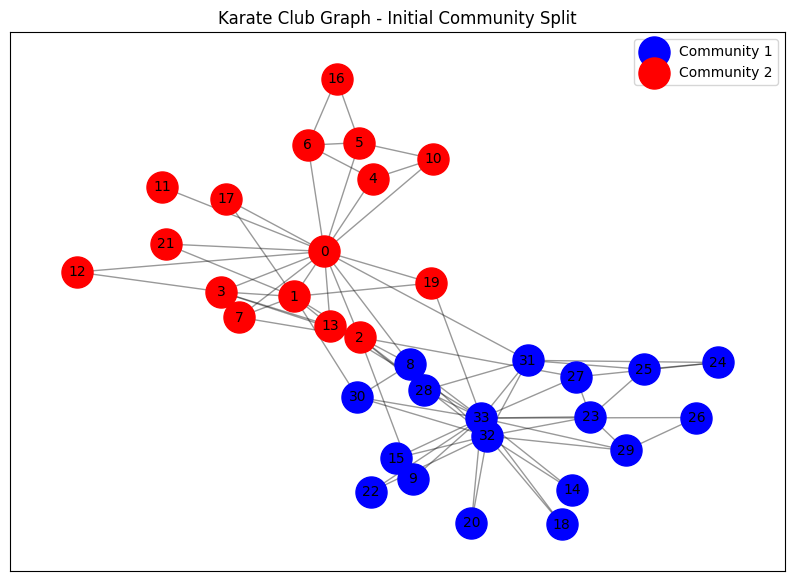

In [59]:
import matplotlib.pyplot as plt
import networkx as nx
g1= {i for i, c in enumerate(communities) if c == 0}
g2= {i for i, c in enumerate(communities) if c == 1}
plt.figure(figsize=(10, 7))
pos = nx.spring_layout(g, seed=42)
nx.draw_networkx_edges(g, pos, alpha=0.4)

nx.draw_networkx_nodes(
    g, pos,
    nodelist=list(g1),
    node_color='blue',
    label='Community 1',
    node_size=500
)

nx.draw_networkx_nodes(
    g, pos,
    nodelist=list(g2),
    node_color='red',
    label='Community 2',
    node_size=500
)

nx.draw_networkx_labels(g, pos, font_size=10)

plt.title("Karate Club Graph - Initial Community Split")
plt.legend()
plt.show()

##Recursive Splitting of the Initial Communities

In this step, both the communities obtained after the first division are examined individually. The restricted modularity matrix is generated for each community, and its highest eigenvalue is then used to find out if further division can be done.

### Formulating the Restricted Modularity Matrices

After obtaining the two communities from the initial partition, we extract the corresponding portions of the original modularity matrix for each group. A diagonal correction based on the row sums is applied to obtain the restricted modularity matrices. These matrices will be used to examine whether either community can be further divided.

In [60]:
nodes1 = sorted(g1)
nodes2 = sorted(g2)
B1 = B[np.ix_(nodes1, nodes1)]
B2 = B[np.ix_(nodes2, nodes2)]
B1 = B1 - np.diag(B1.sum(axis=1))
B2 = B2 - np.diag(B2.sum(axis=1))
print("B1:")
print(B1)
print("B2:")
print(B2)


B1:
[[-5.96153846e-01 -6.41025641e-02 -6.41025641e-02 -6.41025641e-02
  -6.41025641e-02 -6.41025641e-02 -6.41025641e-02 -1.60256410e-01
  -9.61538462e-02 -9.61538462e-02 -6.41025641e-02 -1.28205128e-01
  -9.61538462e-02 -1.28205128e-01  8.71794872e-01 -1.92307692e-01
   6.15384615e-01  4.55128205e-01]
 [-6.41025641e-02 -9.02056208e-17 -2.56410256e-02 -2.56410256e-02
  -2.56410256e-02 -2.56410256e-02 -2.56410256e-02 -6.41025641e-02
  -3.84615385e-02 -3.84615385e-02 -2.56410256e-02 -5.12820513e-02
  -3.84615385e-02 -5.12820513e-02 -5.12820513e-02 -7.69230769e-02
  -1.53846154e-01  7.82051282e-01]
 [-6.41025641e-02 -2.56410256e-02 -1.00000000e+00 -2.56410256e-02
  -2.56410256e-02 -2.56410256e-02 -2.56410256e-02 -6.41025641e-02
  -3.84615385e-02 -3.84615385e-02 -2.56410256e-02 -5.12820513e-02
  -3.84615385e-02 -5.12820513e-02 -5.12820513e-02 -7.69230769e-02
   8.46153846e-01  7.82051282e-01]
 [-6.41025641e-02 -2.56410256e-02 -2.56410256e-02 -1.00000000e+00
  -2.56410256e-02 -2.56410256e-02

### Checking Further Splitting of Group 1

In [51]:
nodes1 = sorted(g1)
B1 = B[np.ix_(nodes1, nodes1)]
B1 = B1 - np.diag(B1.sum(axis=1))
eigv, eigvec = np.linalg.eigh(B1)
idx = np.argmax(eigv)
lambda_max1 = eigv[idx]
v1 = eigvec[:, idx]
print("Largest eigenvalue of Group 1:", lambda_max1)
if lambda_max1 > toll:
    print("Group 1 can be split further.")
else:
    print("Group 1 cannot be split further.")

Largest eigenvalue of Group 1: 0.8594147207778122
Group 1 can be split further.


### Eigenvalue and Eigenvector Calculation for Group 1

The eigenvalues and eigenvectors of the restricted modularity matrix of Group 1 are calculated. The largest eigenvalue indicates whether a further division of this community may improve the modularity.

In [61]:
eigv, eigvec = np.linalg.eigh(B1)

idx = np.argmax(eigv)
lambda_max1 = eigv[idx]
v1 = eigvec[:, idx]
print("Largest eigenvalue of Group 1:", lambda_max1)
print("Corresponding eigenvector:")
print(v1)

Largest eigenvalue of Group 1: 0.8594147207778122
Corresponding eigenvector:
[ 0.41204603  0.07465349  0.12193368  0.12193368  0.12193368  0.12193368
  0.12193368 -0.13993849 -0.4454094  -0.39707241  0.05742313 -0.3004634
 -0.19214954  0.0430569   0.34039034 -0.3059777   0.16135465  0.08241803]


### Further Partitioning of Group 1

The largest eigenvalue is used to determine whether Group 1 can be divided further. If it is positive, the corresponding eigenvector is used to assign nodes into two subcommunities, Group 3 and Group 4, based on the signs of its entries. Otherwise, Group 1 remains unchanged.

In [62]:
if lambda_max1 > toll:
    g3 = {nodes1[i] for i in range(len(nodes1)) if v1[i] >= 0}
    g4 = {nodes1[i] for i in range(len(nodes1)) if v1[i] < 0}
    print("Group 3:", g3)
    print("Group 4:", g4)
    print("Number of nodes in Group 3:", len(g3))
    print("Number of nodes in Group 4:", len(g4))
else:
    print("Group 1 cannot be split further.")

Group 3: {32, 33, 8, 9, 14, 15, 18, 20, 22, 26, 29, 30}
Group 4: {23, 24, 25, 27, 28, 31}
Number of nodes in Group 3: 12
Number of nodes in Group 4: 6


### Modularity Gain of the Split in Group 1

The modularity gain of splitting Group 1 into Group 3 and Group 4 is calculated using the restricted modularity matrix and the sign vector of the corresponding eigenvector. A positive modularity gain indicates that the split improves the modularity of the partition.

In [26]:
Q = 0
for i in g.nodes():
    for j in g.nodes():
        if (i in g1 and j in g1) or (i in g2 and j in g2):
            Q += B[i, j]
Q = Q / (2 * m)

print("Modularity:", Q)

Modularity: 0.3714661406969083


### Verification of Modularity After the Second Split

The modularity of the updated partition is calculated and compared with the modularity before the second split to verify whether dividing Group 1 into Group 3 and Group 4 improves the overall community structure.

In [63]:
Q_verify = nx.community.modularity(g, [g1, g2], weight=None)
print("Modularity using our formula:", Q)
print("Modularity using NetworkX:", Q_verify)
print("Both values match:", np.isclose(Q, Q_verify))

Modularity using our formula: 0.37146614069691
Modularity using NetworkX: 0.37146614069691
Both values match: True


### Visualization After the Second Split

The graph is visualized after the second partitioning step, where Group 1 is divided into Group 3 and Group 4. Group 2 remains unchanged. Different colors are used to distinguish the three communities formed so far.

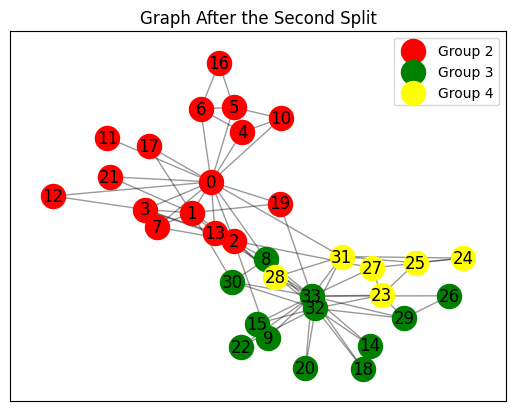

In [64]:
pos = nx.spring_layout(g, seed=42)
nx.draw_networkx_edges(g, pos, alpha=0.4)
nx.draw_networkx_nodes(g, pos, nodelist=list(g2), node_color="red", label="Group 2")
nx.draw_networkx_nodes(g, pos, nodelist=list(g3), node_color="green", label="Group 3")
nx.draw_networkx_nodes(g, pos, nodelist=list(g4), node_color="yellow", label="Group 4")
nx.draw_networkx_labels(g, pos)
plt.title("Graph After the Second Split")
plt.legend()
plt.show()

### Network Metrics After the Second Split

After the second partitioning, the network metrics of the nodes are examined alongside their updated community assignments. Degree centrality, betweenness centrality, closeness centrality and clustering coefficient are calculated on the original graph to understand the structural characteristics of nodes across the three communities.

In [65]:
community = {}
for node in g2:
    community[node] = "Group 2"
for node in g3:
    community[node] = "Group 3"
for node in g4:
    community[node] = "Group 4"
dc = nx.degree_centrality(g)
bc = nx.betweenness_centrality(g)
close = nx.closeness_centrality(g)
clust = nx.clustering(g)
df = pd.DataFrame({
    "Community": [community[i] for i in g.nodes()],
    "Degree Centrality": [dc[i] for i in g.nodes()],
    "Betweenness Centrality": [bc[i] for i in g.nodes()],
    "Closeness Centrality": [close[i] for i in g.nodes()],
    "Clustering Coefficient": [clust[i] for i in g.nodes()]
})

df

,Community,Degree Centrality,Betweenness Centrality,Closeness Centrality,Clustering Coefficient
0,Group 2,0.484848,0.437635,0.568966,0.150000
1,Group 2,0.272727,0.053937,0.485294,0.333333
2,Group 2,0.303030,0.143657,0.559322,0.244444
3,Group 2,0.181818,0.011909,0.464789,0.666667
4,Group 2,0.090909,0.000631,0.379310,0.666667
5,Group 2,0.121212,0.029987,0.383721,0.500000
6,Group 2,0.121212,0.029987,0.383721,0.500000
7,Group 2,0.121212,0.000000,0.440000,1.000000
8,Group 3,0.151515,0.055927,0.515625,0.500000
9,Group 3,0.060606,0.000848,0.434211,0.000000


### Checking Further Splitting of Group 2

In [66]:
nodes2 = sorted(g2)

B2 = B[np.ix_(nodes2, nodes2)]
B2 = B2 - np.diag(B2.sum(axis=1))
eigv, eigvec = np.linalg.eigh(B2)
idx = np.argmax(eigv)
lambda_max2 = eigv[idx]
v2 = eigvec[:, idx]
print("Largest eigenvalue of Group 2:", lambda_max2)
if lambda_max2 > toll:
    print("Group 2 can be split further.")
else:
    print("Group 2 cannot be split further.")

Largest eigenvalue of Group 2: 1.1785377166236144
Group 2 can be split further.


### Eigenvalue and Eigenvector Calculation for Group 2

The eigenvalues and eigenvectors of the restricted modularity matrix of Group 2 are calculated. The largest eigenvalue is used to determine whether Group 2 can be further divided into smaller communities.

In [67]:
eigv, eigvec = np.linalg.eigh(B2)
idx = np.argmax(eigv)
lambda_max2 = eigv[idx]
v2 = eigvec[:, idx]
print("Largest eigenvalue of Group 2:", lambda_max2)
print("Corresponding eigenvector:")
print(v2)

Largest eigenvalue of Group 2: 1.1785377166236144
Corresponding eigenvector:
[ 0.02283549 -0.2207207  -0.46435429 -0.24281471  0.2792228   0.3545833
  0.3545833  -0.23810786  0.2792228   0.03360475 -0.06894851 -0.26800572
  0.35258981 -0.05892482 -0.05584082 -0.05892482]


### Splitting Group 2 into Group 5 and Group 6

In [68]:
if lambda_max2 > toll:
    g5 = {nodes2[i] for i in range(len(nodes2)) if v2[i] >= 0}
    g6 = {nodes2[i] for i in range(len(nodes2)) if v2[i] < 0}
    print("Group 5:", g5)
    print("Group 6:", g6)
    print("Number of nodes in Group 5:", len(g5))
    print("Number of nodes in Group 6:", len(g6))
else:
    print("Group 2 cannot be split further.")

Group 5: {0, 4, 5, 6, 10, 11, 16}
Group 6: {1, 2, 3, 7, 12, 13, 17, 19, 21}
Number of nodes in Group 5: 7
Number of nodes in Group 6: 9


### Modularity Gain After Splitting Group 2

In [69]:
s2 = np.array([1 if node in g5 else -1 for node in nodes2])
Q_gain2 = (s2 @ B2 @ s2) / (4 * m)
print("Modularity gain from splitting Group 2:", Q_gain2)

Modularity gain from splitting Group 2: 0.001232741617356999


### Verification of Modularity Gain for Group 2

In [70]:
Q_before = nx.community.modularity(g, [g3, g4, g2], weight=None)
Q_after = nx.community.modularity(g, [g3, g4, g5, g6], weight=None)
Q_gain2 = Q_after - Q_before
print("Modularity before splitting Group 2:", Q_before)
print("Modularity after splitting Group 2:", Q_after)
print("Modularity gain:", Q_gain2)

Modularity before splitting Group 2: 0.39217619986850755
Modularity after splitting Group 2: 0.3934089414858645
Modularity gain: 0.0012327416173569805


### Visualization After the Third Split



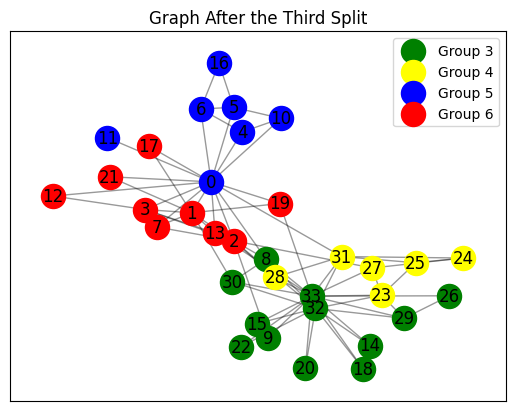

In [71]:
pos = nx.spring_layout(g, seed=42)
nx.draw_networkx_edges(g, pos, alpha=0.4)
nx.draw_networkx_nodes(g, pos, nodelist=list(g3), node_color="green", label="Group 3")
nx.draw_networkx_nodes(g, pos, nodelist=list(g4), node_color="yellow", label="Group 4")
nx.draw_networkx_nodes(g, pos, nodelist=list(g5), node_color="blue", label="Group 5")
nx.draw_networkx_nodes(g, pos, nodelist=list(g6), node_color="red", label="Group 6")
nx.draw_networkx_labels(g, pos)
plt.title("Graph After the Third Split")
plt.legend()
plt.show()

### Centrality Measures After the Third Split

In [72]:
community = {}

for node in g3:
    community[node] = "Group 3"
for node in g4:
    community[node] = "Group 4"
for node in g5:
    community[node] = "Group 5"
for node in g6:
    community[node] = "Group 6"
dc = nx.degree_centrality(g)
bc = nx.betweenness_centrality(g)
close = nx.closeness_centrality(g)
clust = nx.clustering(g)
df = pd.DataFrame({
    "Community": [community[i] for i in g.nodes()],
    "Degree Centrality": [dc[i] for i in g.nodes()],
    "Betweenness Centrality": [bc[i] for i in g.nodes()],
    "Closeness Centrality": [close[i] for i in g.nodes()],
    "Clustering Coefficient": [clust[i] for i in g.nodes()]
})

df

,Community,Degree Centrality,Betweenness Centrality,Closeness Centrality,Clustering Coefficient
0,Group 5,0.484848,0.437635,0.568966,0.150000
1,Group 6,0.272727,0.053937,0.485294,0.333333
2,Group 6,0.303030,0.143657,0.559322,0.244444
3,Group 6,0.181818,0.011909,0.464789,0.666667
4,Group 5,0.090909,0.000631,0.379310,0.666667
5,Group 5,0.121212,0.029987,0.383721,0.500000
6,Group 5,0.121212,0.029987,0.383721,0.500000
7,Group 6,0.121212,0.000000,0.440000,1.000000
8,Group 3,0.151515,0.055927,0.515625,0.500000
9,Group 3,0.060606,0.000848,0.434211,0.000000


In [73]:
Q_final = 0
for i in g.nodes():
    for j in g.nodes():
        if ((i in g3 and j in g3) or
            (i in g4 and j in g4) or
            (i in g5 and j in g5) or
            (i in g6 and j in g6)):
            Q_final += B[i, j]

Q_final = Q_final / (2 * m)
print("Final Modularity:", Q_final)

Final Modularity: 0.3934089414858638


In [46]:
Q_verify = nx.community.modularity(g, [g3, g4, g5, g6], weight=None)
print("Modularity using our formula:", Q_final)
print("Modularity using NetworkX:", Q_verify)
print("Both values match:", np.isclose(Q_final, Q_verify))

Modularity using our formula: 0.3934089414858638
Modularity using NetworkX: 0.3934089414858645
Both values match: True


### Checking Further Splitting of Group 3

In [48]:
nodes3 = sorted(g3)
B3 = B[np.ix_(nodes3, nodes3)]
B3 = B3 - np.diag(B3.sum(axis=1))
eigv, eigvec = np.linalg.eigh(B3)
idx = np.argmax(eigv)
lambda_max3 = eigv[idx]
v3 = eigvec[:, idx]
print("Largest eigenvalue of Group 3:", lambda_max3)
if lambda_max3 > 1e-10:
    print("Group 3 can be split further.")
else:
    print("Group 3 cannot be split further.")

Largest eigenvalue of Group 3: 4.497819820680346e-16
Group 3 cannot be split further.


### Checking Further Splitting of Group 4

In [44]:
nodes4 = sorted(g4)

B4 = B[np.ix_(nodes4, nodes4)]
B4 = B4 - np.diag(B4.sum(axis=1))
eigv, eigvec = np.linalg.eigh(B4)
idx = np.argmax(eigv)
lambda_max4 = eigv[idx]
v4 = eigvec[:, idx]
print("Largest eigenvalue of Group 4:", lambda_max4)
if lambda_max4 > 1e-10:
    print("Group 4 can be split further.")
else:
    print("Group 4 cannot be split further.")

Largest eigenvalue of Group 4: 1.7037223349039733e-16
Group 4 cannot be split further.


### Checking Further Splitting of Group 5

In [43]:
nodes5 = sorted(g5)
B5 = B[np.ix_(nodes5, nodes5)]
B5 = B5 - np.diag(B5.sum(axis=1))
eigv, eigvec = np.linalg.eigh(B5)
idx = np.argmax(eigv)
lambda_max5 = eigv[idx]
v5 = eigvec[:, idx]
print("Largest eigenvalue of Group 5:", lambda_max5)
if lambda_max5 > toll:
    print("Group 5 can be split further.")
else:
    print("Group 5 cannot be split further.")

Largest eigenvalue of Group 5: -5.3363837803477174e-17
Group 5 cannot be split further.


### Checking Further Splitting of Group 6

In [76]:
nodes6 = sorted(g6)

B6 = B[np.ix_(nodes6, nodes6)]
B6 = B6 - np.diag(B6.sum(axis=1))
eigv, eigvec = np.linalg.eigh(B6)
idx = np.argmax(eigv)
lambda_max6 = eigv[idx]
v6 = eigvec[:, idx]
print("Largest eigenvalue of Group 6:", lambda_max6)
if lambda_max6 > toll:
    print("Group 6 can be split further.")
else:
    print("Group 6 cannot be split further.")

Largest eigenvalue of Group 6: 0.0601905003819837
Group 6 can be split further.


### Modularity Matrix for Group 6

In [75]:
print(B6)

[[-5.03846154  0.42307692  0.65384615  0.76923077 -0.11538462  0.71153846
   0.88461538  0.82692308  0.88461538]
 [ 0.42307692 -1.88461538  0.61538462  0.74358974 -0.12820513  0.67948718
  -0.12820513 -0.19230769 -0.12820513]
 [ 0.65384615  0.61538462 -3.57692308  0.84615385  0.92307692  0.80769231
  -0.07692308 -0.11538462 -0.07692308]
 [ 0.76923077  0.74358974  0.84615385 -2.         -0.05128205 -0.12820513
  -0.05128205 -0.07692308 -0.05128205]
 [-0.11538462 -0.12820513  0.92307692 -0.05128205 -0.47435897 -0.06410256
  -0.02564103 -0.03846154 -0.02564103]
 [ 0.71153846  0.67948718  0.80769231 -0.12820513 -0.06410256 -1.78205128
  -0.06410256 -0.09615385 -0.06410256]
 [ 0.88461538 -0.12820513 -0.07692308 -0.05128205 -0.02564103 -0.06410256
  -0.47435897 -0.03846154 -0.02564103]
 [ 0.82692308 -0.19230769 -0.11538462 -0.07692308 -0.03846154 -0.09615385
  -0.03846154 -0.23076923 -0.03846154]
 [ 0.88461538 -0.12820513 -0.07692308 -0.05128205 -0.02564103 -0.06410256
  -0.02564103 -0.03846

### Eigenvalue and Eigenvector Calculation for Group 6

In [74]:
eigv, eigvec = np.linalg.eigh(B6)

idx = np.argmax(eigv)

lambda_max6 = eigv[idx]
v6 = eigvec[:, idx]

print("Largest eigenvalue of Group 6:", lambda_max6)
print("Corresponding eigenvector:")
print(v6)

Largest eigenvalue of Group 6: 0.0601905003819837
Corresponding eigenvector:
[ 0.10473828 -0.26749101 -0.25291194 -0.17710363 -0.42921469 -0.19587701
  0.27356442  0.67073115  0.27356442]


### Splitting Group 6 into Group 7 and Group 8

In [52]:
if lambda_max6 > toll:
    g7 = {nodes6[i] for i in range(len(nodes6)) if v6[i] >= 0}
    g8 = {nodes6[i] for i in range(len(nodes6)) if v6[i] < 0}
    print("Group 7:", g7)
    print("Group 8:", g8)
    print("Number of nodes in Group 7:", len(g7))
    print("Number of nodes in Group 8:", len(g8))
else:
    print("Group 6 cannot be split further.")

Group 7: {1, 19, 21, 17}
Group 8: {2, 3, 7, 12, 13}
Number of nodes in Group 7: 4
Number of nodes in Group 8: 5


### Modularity Gain After Splitting Group 6

In [53]:
s6 = np.array([1 if node in g7 else -1 for node in nodes6])

Q_gain6 = (s6 @ B6 @ s6) / (4 * m)

print("Modularity gain from splitting Group 6:", Q_gain6)

Modularity gain from splitting Group 6: -0.01577909270216962


In [54]:
Q_before = nx.community.modularity(g, [g3, g4, g5, g6], weight=None)

Q_after = nx.community.modularity(g, [g3, g4, g5, g7, g8], weight=None)

Q_gain6 = Q_after - Q_before

print("Modularity before splitting Group 6:", Q_before)
print("Modularity after splitting Group 6:", Q_after)
print("Modularity gain:", Q_gain6)

Modularity before splitting Group 6: 0.3934089414858645
Modularity after splitting Group 6: 0.37762984878369493
Modularity gain: -0.015779092702169595


Since modularity score of splitting of group 6 is negative it is optimal not to split the graph

### Visualization of the Final Community Structure

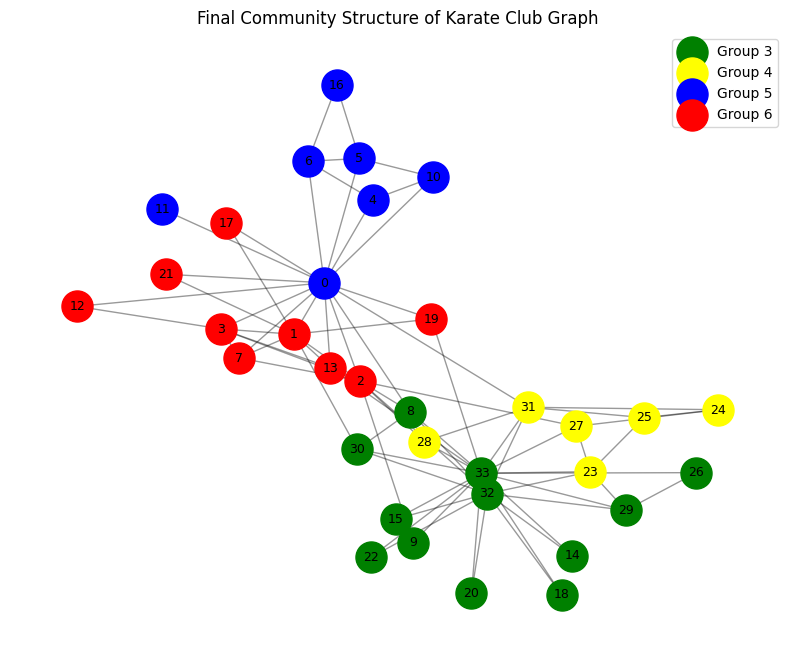

In [78]:
pos = nx.spring_layout(g, seed=42)
plt.figure(figsize=(10, 8))
nx.draw_networkx_edges(g, pos, alpha=0.4)
nx.draw_networkx_nodes(g, pos, nodelist=list(g3),
                       node_color="green", label="Group 3", node_size=500)
nx.draw_networkx_nodes(g, pos, nodelist=list(g4),
                       node_color="yellow", label="Group 4", node_size=500)
nx.draw_networkx_nodes(g, pos, nodelist=list(g5),
                       node_color="blue", label="Group 5", node_size=500)
nx.draw_networkx_nodes(g, pos, nodelist=list(g6),
                       node_color="red", label="Group 6", node_size=500)
nx.draw_networkx_labels(g, pos, font_size=9)
plt.title("Final Community Structure of Karate Club Graph")
plt.legend()
plt.axis("off")
plt.show()

##Final Modularity score

In [79]:
Q_final = nx.community.modularity(g, [g3, g4, g5, g6], weight=None)

print("Final Modularity Score:", Q_final)

Final Modularity Score: 0.3934089414858645


## Evolution of Network Metrics Across Iterations

This section examines how the network structure changes as recursive spectral
partitioning is performed. The number of communities and modularity score are
recorded at each iteration.

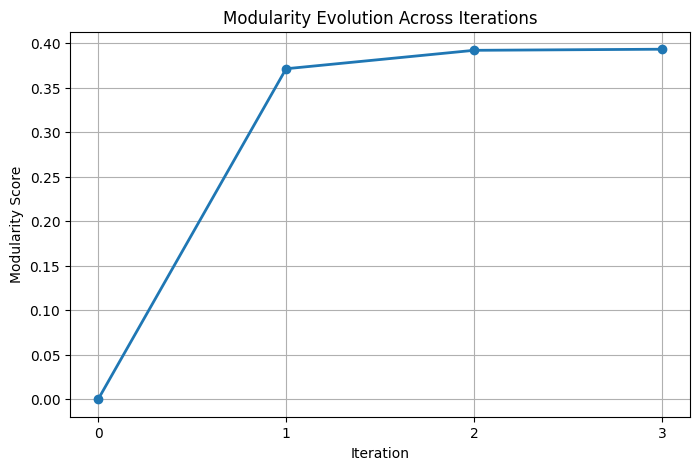

Modularity scores: [0.0, 0.37146614069691, 0.39217619986850755, 0.3934089414858645]


In [81]:
partitions = [
    [set(g.nodes())],
    [g1, g2],
    [g3, g4, g2],
    [g3, g4, g5, g6]
]

iterations = [0, 1, 2, 3]

modularity_scores = [
    nx.community.modularity(g, p, weight=None)
    for p in partitions
]

plt.figure(figsize=(8, 5))
plt.plot(iterations, modularity_scores, marker='o', linewidth=2)

plt.xlabel("Iteration")
plt.ylabel("Modularity Score")
plt.title("Modularity Evolution Across Iterations")
plt.xticks(iterations)
plt.grid(True)

plt.show()

print("Modularity scores:", modularity_scores)

##Final Community Membership

In [83]:
community_members = {
    "Group 3": sorted(g3),
    "Group 4": sorted(g4),
    "Group 5": sorted(g5),
    "Group 6": sorted(g6)
}

for group, members in community_members.items():
    print(group, ":", members)
    print("Number of members:", len(members))
    print()

Group 3 : [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
Number of members: 12

Group 4 : [23, 24, 25, 27, 28, 31]
Number of members: 6

Group 5 : [0, 4, 5, 6, 10, 11, 16]
Number of members: 7

Group 6 : [1, 2, 3, 7, 12, 13, 17, 19, 21]
Number of members: 9



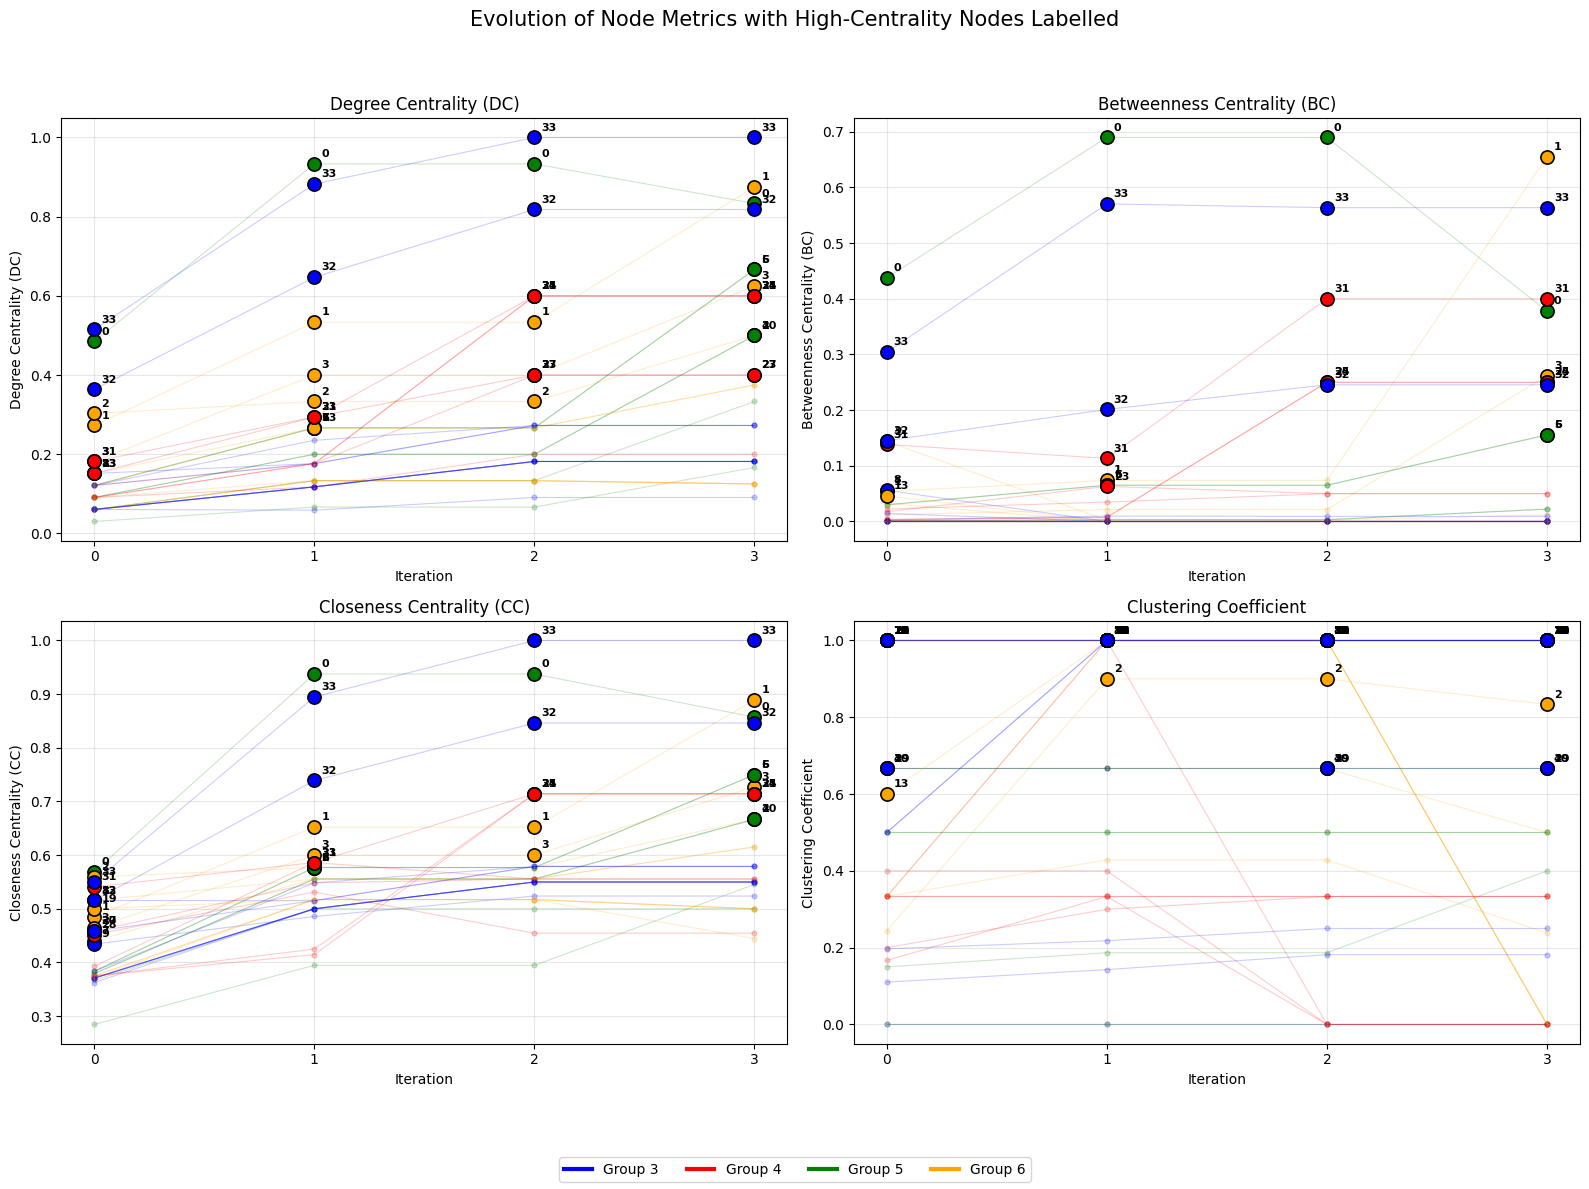

In [91]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, (name, node_values) in zip(
    axes.flatten(), metric_evolution.items()
):

    avg_values = [
        np.mean([node_values[node][i] for node in g.nodes()])
        for i in range(len(iterations))
    ]

    for node, values in node_values.items():
        group = final_community[node]

        ax.plot(
            iterations,
            values,
            color=colors[group],
            alpha=0.2,
            linewidth=0.8
        )

        ax.scatter(
            iterations,
            values,
            color=colors[group],
            s=12,
            alpha=0.2
        )

        for i in range(len(iterations)):
            if values[i] > avg_values[i]:
                ax.scatter(
                    iterations[i],
                    values[i],
                    color=colors[group],
                    s=90,
                    edgecolors="black",
                    linewidths=1.2,
                    zorder=3
                )

                ax.annotate(
                    str(node),
                    (iterations[i], values[i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                    fontweight="bold"
                )

    ax.set_title(name)
    ax.set_xlabel("Iteration")
    ax.set_ylabel(name)
    ax.set_xticks(iterations)
    ax.grid(True, alpha=0.3)

legend_items = [
    Line2D([0], [0], color=colors[group], lw=3, label=group)
    for group in community_members
]

fig.legend(handles=legend_items, loc="lower center", ncol=4)

fig.suptitle(
    "Evolution of Node Metrics with High-Centrality Nodes Labelled",
    fontsize=15
)

plt.tight_layout(rect=[0, 0.07, 1, 0.95])
plt.show()

#Conclusion
This project  used recursive spectral modularity partitioning on Zachary's Karate Club graph to partition communities in the network. In its raw form, the graph contained 34 nodes and 78 edges.

Recursive partitioning of the network was done through division of the network using the leading eigenvector of the modularity matrix. In the first partition, there were two groups g1 and g2  that further split into four communities g3, g4, g5, and g6.

The final modularity of the network is

 $
\boxed{Q=0.39340894}$


Further splits of the network were attempted using the largest eigenvalue of the restricted modularity matrix of each community. While group 6 has a positive leading eigenvalue, splitting it into two sub-groups gave negative modularity gain of about \$(-0.01578\)$. Thus, it was not accepted.

The resulting network is divided into four communities, and the modularity value is 0.3934.

## Discussion
The results indicate that the Karate Club network has a community structure that can be found using recursive spectral modularity partitioning. This community was further divided into four communities: Group 3, Group 4, Group 5, and Group 6. The value of modularity at the end is 0.3934, which indicates that there is a fairly good community structure, but some links still exist between different communities.
A positive maximum eigenvalue does not imply that the split will enhance the global modularity. For instance, Group 6 could be divided further since its maximum eigenvalue was 0.06019,but  dividing the group into two smaller groups would result in a modularity loss of about −0.01578. The implication is that the division is not an improvement to the community structure.
nodes 0,33,32,1 have high centrality through out iterations
On balance, the findings have shown that recursive spectral partitioning is a technique that can help identify community structure in a network. The use of modularity measure together with node-centrality measures is a more complete way of analyzing community structure and node centrality.